# Optimizing a waterflood with Everest's optimizer

This notebook continues where `ensemble_smoother.ipynb` left off. There, observations
of the first 960 days of a waterflood narrowed down the permeability of the reservoir
to a posterior ensemble. Here we use that ensemble to *decide* something: how hard to
produce each well over the remaining 1440 days, so as to maximize the expected net
present value (NPV) of the field.

In [1]:
import iterative_ensemble_smoother as ies
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from minires import Grid2D, ResSim
from minires.geostat import gaussian_fields
from ropt.simple import optimize

## The reservoir and its forward model

The same reservoir as in the previous notebook, with one change: the injector is now
held at a pressure of 400 bar instead of a fixed rate. How much water it manages to
push in then depends on how hard the producers pull, so that the producers' bottom-hole
pressures (BHP) decide the throughput of the whole field, and not only how it is
shared between them.

The forward model takes a BHP for each producer, which applies after the history
period; during the history every producer was at 250 bar. It returns the water cut of
each producer, as before, and now also the liquid rates of all wells, which the NPV
needs.

In [2]:
from itertools import starmap

nx = ny = 32  # cells
lx = 1000.0  # extent [m]
dz = 20.0  # thickness [m]
porosity = 0.2

fluid = {"vw": 1.0, "vo": 5.0, "swc": 0.2, "sor": 0.2, "nw": 2, "no": 2}
injector = {"INJ": (0.5 * lx, 0.5 * lx)}
producers = {
    "PROD1": (0.15 * lx, 0.15 * lx),
    "PROD2": (0.85 * lx, 0.15 * lx),
    "PROD3": (0.15 * lx, 0.85 * lx),
    "PROD4": (0.85 * lx, 0.85 * lx),
}
injector_bhp = 400.0  # [bar]
history_bhp = 250.0  # producer BHP during the history [bar]

dt = 60.0  # [days]
nsteps = 40
nsteps_history = 16
nsteps_forecast = nsteps - nsteps_history
obs_steps = np.arange(4, nsteps_history + 1, 4)
days = dt * np.arange(1, nsteps + 1)

grid = Grid2D(Lx=lx, Ly=lx, Nx=nx, Ny=ny)

In [3]:
class Reservoir(ResSim):
    def well_controls(self, S, P, k):
        controls = super().well_controls(S, P, k)
        if P is not None:
            cell_pressure = P[self.xy2ind(*self.wells.xy.T)]
            is_producer = np.array([name in producers for name in self.wells.names])
            shut_in = is_producer & (cell_pressure < controls["bhp"] + 2.0)
            controls["bhp"][shut_in] = np.nan
            controls["rates"][shut_in] = 0.0
        return controls


def simulate(log_permeability, forecast_bhp):
    """Run the flood with the given producer BHPs over the forecast period.

    Returns the water cut of the producers, (nsteps, 4), the liquid rate they
    produce, (nsteps, 4), and the rate the injector injects, (nsteps,), in m3/day.
    """
    wells = {
        name: {"xy": list(xy), "bhp": injector_bhp, "rw": 0.15}
        for name, xy in injector.items()
    } | {
        name: {
            "xy": list(xy),
            "bhp": np.r_[
                np.full(nsteps_history, history_bhp), np.full(nsteps_forecast, bhp)
            ],
            "rw": 0.15,
        }
        for (name, xy), bhp in zip(producers.items(), forecast_bhp, strict=True)
    }
    model = Reservoir(
        Lx=lx,
        Ly=lx,
        Nx=nx,
        Ny=ny,
        cdarcy=0.008527,
        K=np.exp(log_permeability).reshape(nx, ny),
        por=np.full((nx, ny), porosity),
        ct=1e-5,
        fluid=fluid,
        wells=wells,
    )
    saturation, _ = model.sim(
        dt,
        nsteps,
        S0=np.full(model.Nxy, fluid["swc"]),
        P0=np.full(model.Nxy, 300.0),
        pbar=False,
    )
    cells = list(starmap(model.xy2ind, producers.values()))
    water_cut = np.array(
        [model.fluid.fractional_flow(s)[cells] for s in saturation[1:]]
    )
    rates = model.wells.actual_rates.T * dz
    return water_cut, -rates[:, 1:], rates[:, 0]

## History matching

This is the same previous notebook. See `ensemble_smoother.ipynb` for details.

In [4]:
perm_mean = 200.0  # [mD]
perm_std = 0.8  # standard deviation of log(K)
corr_length = 300.0  # [m]
ensemble_size = 50


def sample_log_permeability(n, rng):
    fields = gaussian_fields(grid.mesh, n, corr_length, rng)
    return np.log(perm_mean) + perm_std * fields


rng = np.random.default_rng(20220906)
truth = sample_log_permeability(1, rng)[0]
X_prior = sample_log_permeability(ensemble_size, rng).T

In [5]:
history_controls = np.full(len(producers), history_bhp)

truth_water_cut, _, _ = simulate(truth, history_controls)
obs_true = truth_water_cut[obs_steps - 1]
obs_std = np.maximum(0.05 * obs_true, 0.02)
obs_values = np.clip(obs_true + rng.normal(scale=obs_std), 0, 1)

Y_prior = np.array(
    [simulate(x, history_controls)[0][obs_steps - 1].ravel() for x in X_prior.T]
).T

In [6]:
smoother = ies.ESMDA(
    covariance=obs_std.ravel() ** 2,
    observations=obs_values.ravel(),
    alpha=1,
    seed=42,
)
smoother.prepare_assimilation(Y=Y_prior)
X_posterior = smoother.assimilate_batch(X=X_prior)

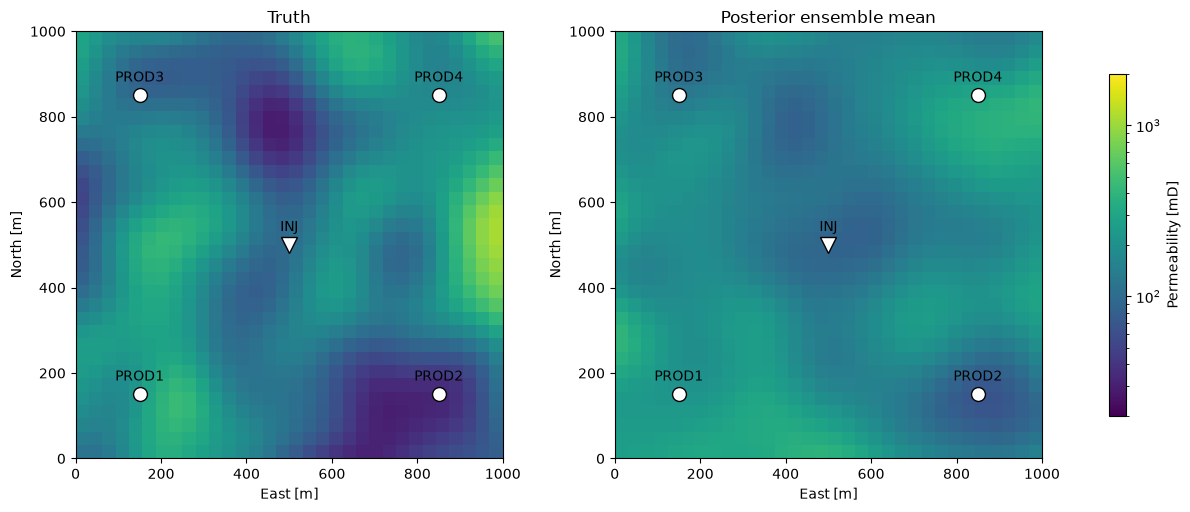

In [7]:
def plot_wells(ax):
    for name, (east, north) in injector.items():
        ax.plot(east, north, "v", color="white", mec="black", ms=12)
        ax.annotate(name, (east, north), (0, 10), "data", "offset points", ha="center")
    for name, (east, north) in producers.items():
        ax.plot(east, north, "o", color="white", mec="black", ms=10)
        ax.annotate(name, (east, north), (0, 10), "data", "offset points", ha="center")


def plot_permeability(ax, log_permeability, title):
    image = ax.imshow(
        np.exp(log_permeability).reshape(nx, ny).T,
        origin="lower",
        extent=(0, lx, 0, lx),
        norm=LogNorm(vmin=20, vmax=2000),
        cmap="viridis",
    )
    plot_wells(ax)
    ax.set(title=title, xlabel="East [m]", ylabel="North [m]")
    return image


fig, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained")
plot_permeability(axes[0], truth, "Truth")
image = plot_permeability(axes[1], X_posterior.mean(axis=1), "Posterior ensemble mean")
fig.colorbar(image, ax=axes, label="Permeability [mD]", shrink=0.8)
plt.show()

## The objective: net present value

Oil sells; water costs money to lift, separate and dispose of; and injecting it costs
money too. Every report step earns a cash flow, which is discounted back to the start
of the flood at 8 % per year, and the NPV is their sum. 

In [8]:
oil_price = 400.0  # USD per m3 (about 63 USD per barrel)
water_prod_cost = 30.0  # USD per m3 produced
water_inj_cost = 10.0  # USD per m3 injected
discount_rate = 0.08  # per year


def npv(water_cut, liquid_rate, injection_rate):
    """Net present value in million USD of one simulated flood."""
    oil = (liquid_rate * (1 - water_cut)).sum(axis=1)
    water = (liquid_rate * water_cut).sum(axis=1)
    cash_flow = dt * (
        oil_price * oil - water_prod_cost * water - water_inj_cost * injection_rate
    )
    discount = (1 + discount_rate) ** (-days / 365.25)
    return (cash_flow * discount).sum() / 1e6


truth_npv = npv(*simulate(truth, history_controls))
print(f"NPV of the truth at the history BHPs: {truth_npv:.1f} MUSD")

NPV of the truth at the history BHPs: 367.3 MUSD


## The controls

The controls are the four producer BHPs over the forecast period, each allowed
between 150 and 290 bar. A low BHP pulls hard: more oil now, but more water with it,
and water that would otherwise have swept oil towards another well. A high BHP chokes
the well.

In [9]:
realizations = X_posterior
bhp_bounds = (150.0, 290.0)


def expected_npv(controls):
    return np.mean([npv(*simulate(x, controls)) for x in realizations.T])


def objective(controls, context):
    """The NPV of one realization at one set of controls, as ropt calls for it."""
    return npv(*simulate(realizations[:, context.realization], controls))

## Running the optimization

`ropt` is configured:
the variables and their bounds, that the objective is to be maximized, the weights of
the realizations (equal), how the gradient is estimated, and which optimizer to use.
We use SciPy's SLSQP for simplicity.

The `report` callback is called with every evaluation of the objective (not the
perturbed ones), which is how we follow the optimizer's progress.

In [10]:
config = {
    "variables": {
        "variable_count": len(producers),
        "lower_bounds": bhp_bounds[0],
        "upper_bounds": bhp_bounds[1],
        "perturbation_magnitudes": 10.0,  # [bar]
    },
    "objectives": {"maximize": True},
    "realizations": {"weights": np.ones(realizations.shape[1])},
    "gradient": {"number_of_perturbations": 4},
    "optimizer": {"max_batches": 15},
    "backend": {"method": "scipy/slsqp"},
}

progress = []


def report(results):
    controls = results.variables
    expected = results.functions.objectives[0]
    progress.append((controls.copy(), expected))
    print(f"batch {results.batch_id:2d}  {np.round(controls, 1)}  NPV {expected:.1f}")


result = optimize(config, history_controls, objective, report=report)
optimal_controls = result.results.variables
print(f"\nStopped with {result.exit_code.name}")

batch  0  [250. 250. 250. 250.]  NPV 371.0
batch  2  [250.  249.8 249.8 250.1]  NPV 371.1
batch  4  [249.6 248.8 248.8 250.7]  NPV 371.6
batch  6  [248.1 244.2 244.2 253.2]  NPV 373.6
batch  8  [242.4 227.1 227.  262.9]  NPV 379.4
batch 10  [232.2 196.1 196.1 280.1]  NPV 383.4
batch 12  [233.5 200.  200.1 277.7]  NPV 383.3
batch 13  [232.6 197.3 197.3 279.4]  NPV 383.4
batch 14  [232.3 196.5 196.5 279.9]  NPV 383.4

Stopped with MAX_BATCHES_REACHED


The optimizer first probes near the starting point, then strides towards higher NPV
until the gain per batch flattens out or the batch budget is spent. The expected NPV
it reports is the average over the realizations.

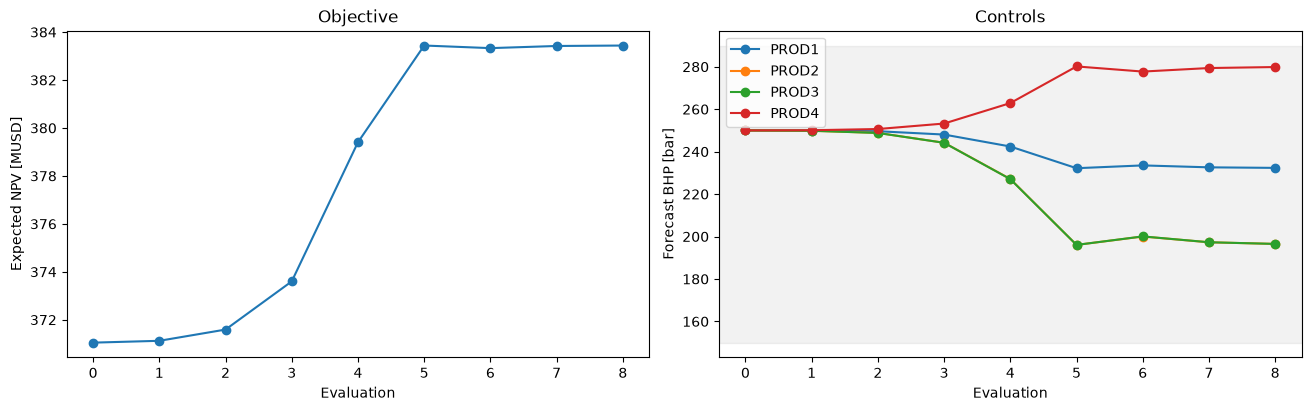

In [11]:
controls_path = np.array([c for c, _ in progress])
expected_path = np.array([e for _, e in progress])

fig, axes = plt.subplots(1, 2, figsize=(13, 4), layout="constrained")
axes[0].plot(expected_path, "o-")
axes[0].set(xlabel="Evaluation", ylabel="Expected NPV [MUSD]", title="Objective")
for i, name in enumerate(producers):
    axes[1].plot(controls_path[:, i], "o-", label=name)
axes[1].axhspan(*bhp_bounds, color="gray", alpha=0.1)
axes[1].set(xlabel="Evaluation", ylabel="Forecast BHP [bar]", title="Controls")
axes[1].legend()
plt.show()

## What did we decide, and was it right?

The controls the optimizer settled on tell a story about the reservoir: the producers
that the history match says water out early are choked, the ones with oil still to
sweep are opened up. Since this is a synthetic case we can also check the decision
against the truth, and compare.

In [12]:
for name, bhp in zip(producers, optimal_controls, strict=True):
    print(f"{name}: {bhp:6.1f} bar")

truth_before = simulate(truth, history_controls)
truth_after = simulate(truth, optimal_controls)
print()
print(f"Expected NPV: {expected_path[0]:.1f} -> {expected_path[-1]:.1f} MUSD")
print(f"NPV on truth: {npv(*truth_before):.1f} -> {npv(*truth_after):.1f} MUSD")

PROD1:  232.2 bar
PROD2:  196.1 bar
PROD3:  196.1 bar
PROD4:  280.1 bar

Expected NPV: 371.0 -> 383.4 MUSD
NPV on truth: 367.3 -> 379.8 MUSD


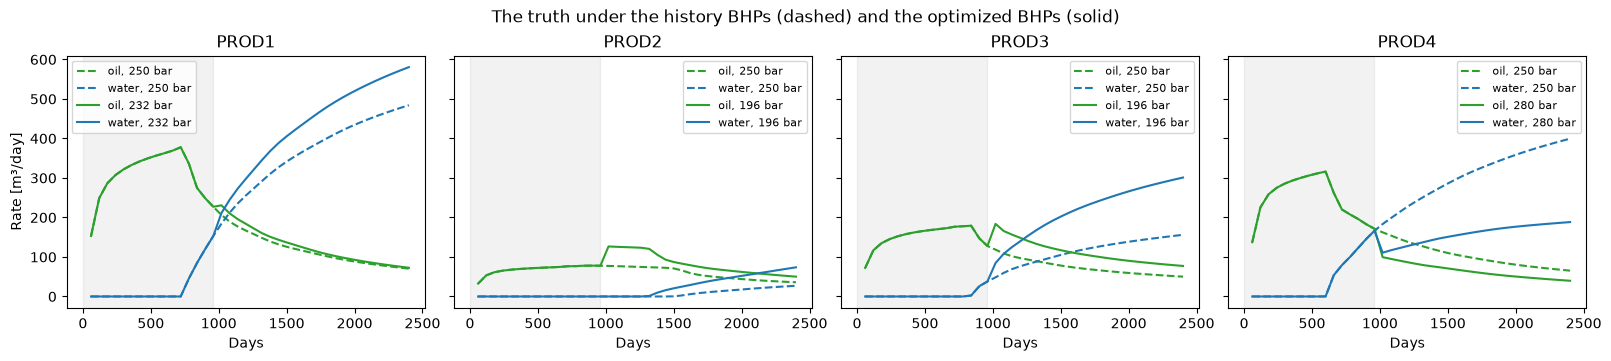

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True, layout="constrained")
for i, (ax, name) in enumerate(zip(axes, producers, strict=True)):
    for (water_cut, liquid, _), label, style in [
        (truth_before, f"{history_bhp:.0f} bar", "--"),
        (truth_after, f"{optimal_controls[i]:.0f} bar", "-"),
    ]:
        water = liquid[:, i] * water_cut[:, i]
        oil = liquid[:, i] - water
        ax.plot(days, oil, style, color="C2", label=f"oil, {label}")
        ax.plot(days, water, style, color="C0", label=f"water, {label}")
    ax.axvspan(0, dt * nsteps_history, color="gray", alpha=0.1)
    ax.set(title=name, xlabel="Days")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Rate [m³/day]")
fig.suptitle("The truth under the history BHPs (dashed) and the optimized BHPs (solid)")
plt.show()